# Formative 2 - Multimodal Data Preprocessing
## Part 4: Models, Evaluation and System Simulation

**Project component:** the three models and the user identity and product recommendation system that chains them.

### Objectives
1. Train and evaluate the **facial recognition model** on `datasets/image_features.csv`.
2. Train and evaluate the **voiceprint verification model** on `datasets/audio_features.csv`.
3. Train and evaluate the **product recommendation model** on `datasets/merged_customer_recommendation_dataset.csv`.
4. Report accuracy, F1-score and loss for each, and explain the multimodal decision logic.
5. Simulate a full authorised transaction and unauthorised attempts, exactly as the command-line app does.

### System flow
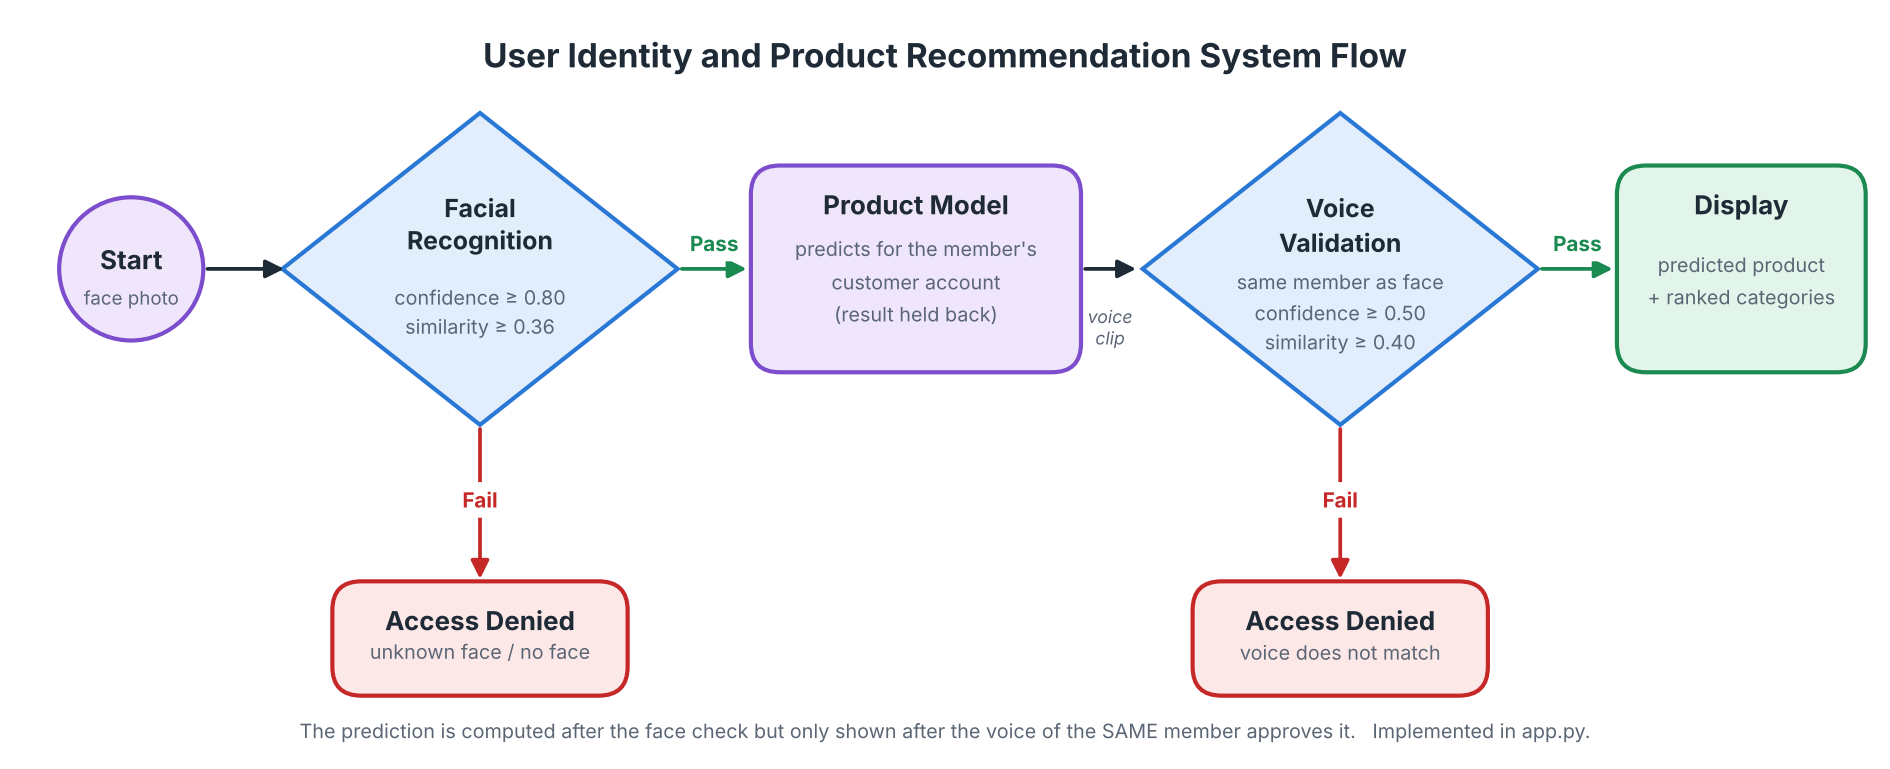

The training code lives in [`src/face_model.py`](../src/face_model.py), [`src/voice_model.py`](../src/voice_model.py),
[`src/product_model.py`](../src/product_model.py) and the shared [`src/verification.py`](../src/verification.py). The
command-line app is [`app.py`](../app.py). This notebook calls the same functions, so its numbers are the app's numbers.

## 1. Environment setup

This cell makes the notebook run anywhere without manual steps:

* **Locally** (Jupyter, VS Code, PyCharm on Windows, macOS or Linux) it finds the repository folder from wherever the
  notebook is opened.
* **On Google Colab, Kaggle or any other hosted notebook** it clones the repository first.
* It installs only the packages from `requirements.txt` that are missing, so an existing setup is never changed.

All file paths are relative to the repository, so nothing needs to be edited before running.

In [1]:
import importlib
import os
import subprocess
import sys
import warnings
from pathlib import Path

# The GitHub repository this notebook belongs to (only used when the notebook is opened on its own).
REPO_URL = os.environ.get("F2_REPO_URL", "https://github.com/mutaganzwa-desire/multimodal_data_preprocessing.git")
REQUIRED_FILES = ["app.py", "src/environment.py", "src/media_io.py", "src/verification.py"]


def missing_files(folder: Path) -> list:
    return [f for f in REQUIRED_FILES if not (folder / f).exists()]


def find_repo_root() -> Path:
    """Return the repository folder, cloning or updating it when needed.

    * Opened from inside a clone (Jupyter, VS Code or PyCharm on Windows, macOS or Linux): that clone is used.
    * Opened on its own (Google Colab, Kaggle, a downloaded .ipynb): the repository is cloned next to the
      notebook, and an older copy left there by a previous run is updated with `git pull`.
    """
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if not missing_files(folder):
            return folder
    target = Path.cwd() / "multimodal_data_preprocessing"
    if (target / ".git").exists():
        subprocess.run(["git", "-C", str(target), "pull", "-q", "--ff-only"], check=False)
    elif not target.exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO_URL, str(target)], check=True)
    missing = missing_files(target)
    if missing:
        raise FileNotFoundError(
            f"The repository copy in {target} has no {', '.join(missing)}: it is older than this notebook. "
            "Push the latest commits to GitHub, delete that folder (on Colab: Runtime > Disconnect and delete "
            "runtime), and run this cell again."
        )
    return target


REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)
sys.path.insert(0, str(REPO_ROOT))
for name in [m for m in sys.modules if m == "src" or m.startswith("src.")]:
    del sys.modules[name]  # forget modules imported from another copy in an earlier run
importlib.invalidate_caches()

from src.environment import ensure_packages

ensure_packages()  # installs only the packages that are missing, then does nothing on later runs
warnings.filterwarnings("ignore", category=FutureWarning)
print("Repository folder:", REPO_ROOT.name)

All required packages are available.
Repository folder: multimodal_data_preprocessing


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import face_model, product_model, voice_model
from src.model_store import save

pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 80
# Categorical colours in a fixed order (colour-blind checked); markers add a second cue.
ATTEMPT_STYLE = {
    "genuine": ("#2a78d6", "o", "genuine member"),
    "teammate": ("#eb6834", "s", "teammate claiming to be someone else"),
    "outsider": ("#1baf7a", "^", "stranger (member left out of training)"),
}


def show_comparison(metrics, title):
    table = pd.DataFrame(metrics["comparison"]).T
    table["selected"] = np.where(table.index == metrics["selected_model"], "<- lowest log loss", "")
    print(title)
    display(table.round(3))


def plot_confusion(ax, matrix, labels, title):
    matrix = np.array(matrix)
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(labels)), labels, rotation=30, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.set_xlabel("predicted")
    ax.set_ylabel("actual")
    ax.set_title(title)
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, matrix[i, j], ha="center", va="center",
                    color="white" if matrix[i, j] > matrix.max() / 2 else "black")


def plot_decision(ax, model, title):
    """Every held-out attempt as (classifier probability, similarity), with the acceptance region."""
    scores = model.metrics["attempt_scores"]
    for kind, (colour, marker, label) in ATTEMPT_STYLE.items():
        pts = np.array(scores[kind])
        if len(pts):
            ax.scatter(pts[:, 0], pts[:, 1], s=36, c=colour, marker=marker, alpha=0.6,
                       edgecolor="white", linewidth=0.6, label=f"{label} ({len(pts)})")
    ax.axvline(model.prob_threshold, color="#52514e", lw=1, ls="--")
    ax.axhline(model.sim_threshold, color="#52514e", lw=1, ls="--")
    ax.fill_between([model.prob_threshold, 1.02], model.sim_threshold, 1.02, color="#2a78d6", alpha=0.06)
    ax.text(1.0, 1.0, "accepted", ha="right", va="top", color="#52514e")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(min(-0.3, ax.get_ylim()[0]), 1.02)
    ax.set_xlabel("classifier probability for the claimed member")
    ax.set_ylabel("similarity to the claimed member's samples")
    ax.set_title(title)
    ax.legend(fontsize=8, loc="lower right")

## 2. How the face and voice models decide

Both biometric models are built by the same procedure in `src/verification.py`:

1. **Compare three model families** (Logistic Regression, Random Forest, XGBoost) with leave-one-group-out
   cross-validation. A group is one source photo or one recording, so all augmented copies of a sample are always on the
   same side of the split; a random row split would test the model on near-copies of its training data.
2. **Keep the model with the lowest log loss.** Log loss rewards well-calibrated probabilities, which matter here
   because the decision uses a probability threshold.
3. **Add an outsider check.** A classifier always names one of the members it knows, even for a stranger. So a sample is
   accepted only if (a) the classifier's probability for the claimed member is high enough *and* (b) the sample's mean
   cosine similarity to that member's 3 closest enrolled feature vectors is high enough.
4. **Choose both thresholds on held-out attempts** of three kinds: genuine members, teammates claiming to be another
   member, and strangers (each member removed from training in turn and presented as unknown). The thresholds maximise
   the average of the genuine acceptance rate, the teammate rejection rate and the stranger rejection rate.

## 3. Facial recognition model

In [3]:
face = face_model.train()
save(face, face_model.MODEL_PATH)
show_comparison(face.metrics, "Face model: leave-one-photo-out cross-validation")

[face] cross-validated comparison (leave one source_image out):
                     accuracy  f1_macro  log_loss
logistic_regression     0.917     0.914     0.177
random_forest           0.906     0.901     0.636
xgboost                 0.802     0.791     0.614
[face] selected: logistic_regression (lowest log loss)
[face] thresholds: probability >= 0.80, similarity >= 0.36 | genuine accepted 91%, teammates rejected 100%, outsiders rejected 99%
Face model: leave-one-photo-out cross-validation


,accuracy,f1_macro,log_loss,selected
logistic_regression,0.917,0.914,0.177,<- lowest log loss
random_forest,0.906,0.901,0.636,
xgboost,0.802,0.791,0.614,


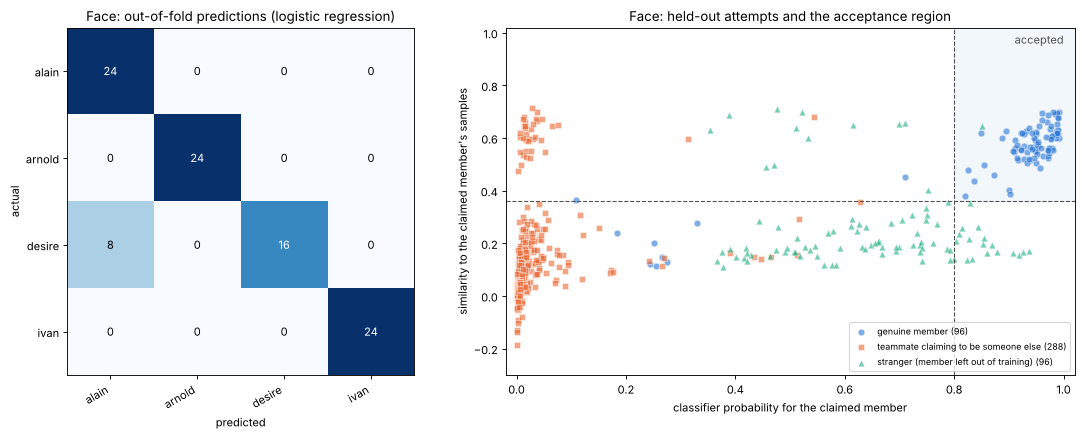

,genuine_accept_rate,teammate_reject_rate,outsider_reject_rate,genuine_accept_rate_unmodified,prob_threshold,sim_threshold,n_genuine,n_teammate,n_outsider
face verification,0.906,1.0,0.99,0.917,0.8,0.36,96.0,288.0,96.0


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
plot_confusion(axes[0], face.metrics["confusion_matrix"], face.classes,
               f"Face: out-of-fold predictions ({face.model_name.replace('_', ' ')})")
plot_decision(axes[1], face, "Face: held-out attempts and the acceptance region")
fig.tight_layout()
plt.show()
display(pd.Series(face.metrics["verification"]).to_frame("face verification").T.round(3))

**Interpretation:** Logistic Regression is best on all three metrics (accuracy 0.917, F1 0.914, log loss 0.177). Its
only errors are the 8 versions of `desire_neutral.jpg`, the one photo taken in different light from Desire's others.
The scatter plot shows why two checks are needed: strangers often get a high probability for some member, but a low
similarity. Result: 91% of genuine attempts accepted, 100% of teammates and 99% of strangers rejected.

## 4. Voiceprint verification model

In [5]:
voice = voice_model.train()
save(voice, voice_model.MODEL_PATH)
show_comparison(voice.metrics, "Voice model: leave-one-recording-out cross-validation")

[voice] cross-validated comparison (leave one source_clip out):
                     accuracy  f1_macro  log_loss
logistic_regression     0.724     0.629     1.002
random_forest           0.582     0.479     1.164
xgboost                 0.622     0.539     1.451
[voice] selected: logistic_regression (lowest log loss)
[voice] thresholds: probability >= 0.50, similarity >= 0.40 | genuine accepted 66%, teammates rejected 94%, outsiders rejected 80%
Voice model: leave-one-recording-out cross-validation


,accuracy,f1_macro,log_loss,selected
logistic_regression,0.724,0.629,1.002,<- lowest log loss
random_forest,0.582,0.479,1.164,
xgboost,0.622,0.539,1.451,


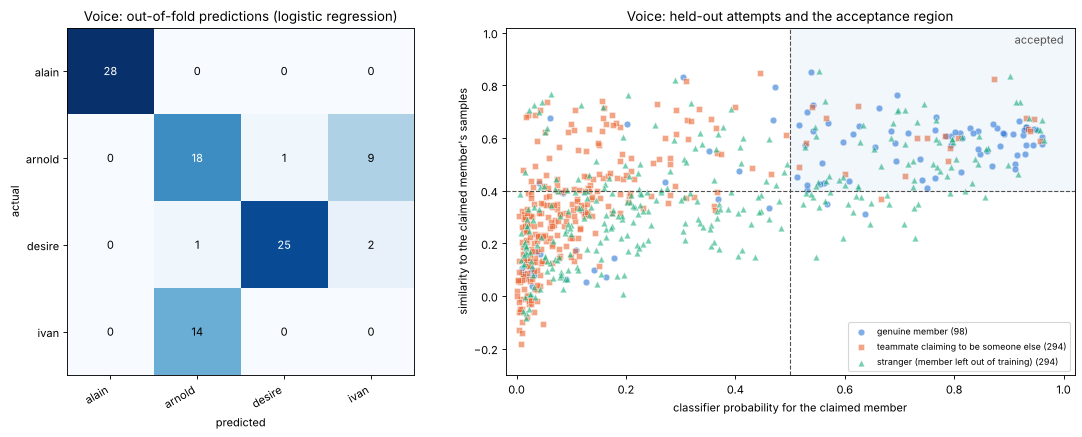

,genuine_accept_rate,teammate_reject_rate,outsider_reject_rate,genuine_accept_rate_unmodified,prob_threshold,sim_threshold,n_genuine,n_teammate,n_outsider
voice verification,0.663,0.935,0.796,0.786,0.5,0.4,98.0,294.0,294.0


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.4]})
plot_confusion(axes[0], voice.metrics["confusion_matrix"], voice.classes,
               f"Voice: out-of-fold predictions ({voice.model_name.replace('_', ' ')})")
plot_decision(axes[1], voice, "Voice: held-out attempts and the acceptance region")
fig.tight_layout()
plt.show()
display(pd.Series(voice.metrics["verification"]).to_frame("voice verification").T.round(3))

**Interpretation:** Logistic Regression is best (accuracy 0.724, F1 0.629, log loss 1.002). Alain and Desire are
recognised well. Arnold and Ivan are often confused, and Ivan's held-out recordings are all taken for Arnold because he
has only one recording per phrase. The voice check rejects 94% of teammates and 80% of strangers, and accepts 66% of
genuine attempts (79% on unmodified recordings). It is the weaker check; more recordings per member would help most.

## 5. Product recommendation model

Features are the customer's aggregated social-media profile (engagement, purchase interest, sentiment shares, number
of platforms, dominant platform) and the visit date (month, day of week). The purchase amount and rating are left out
because they only exist after the purchase. Folds are grouped by `customer_id`, so a customer's purchases are never
split between training and testing, and the 5-fold split is repeated 5 times with different shuffles to get a stable
estimate on only 150 transactions. A most-frequent-class baseline shows what "no signal" looks like.

In [7]:
product = product_model.train()
save(product, product_model.MODEL_PATH)

[product] 5x repeated 5-fold CV grouped by customer_id:
                        accuracy_mean  accuracy_std  f1_macro_mean  f1_macro_std  log_loss_mean
baseline_most_frequent          0.163         0.026          0.088         0.012          1.642
logistic_regression             0.243         0.035          0.224         0.037          1.698
random_forest                   0.219         0.034          0.188         0.027          1.750
xgboost                         0.195         0.028          0.179         0.024          1.890
[product] selected: logistic_regression (best macro F1)


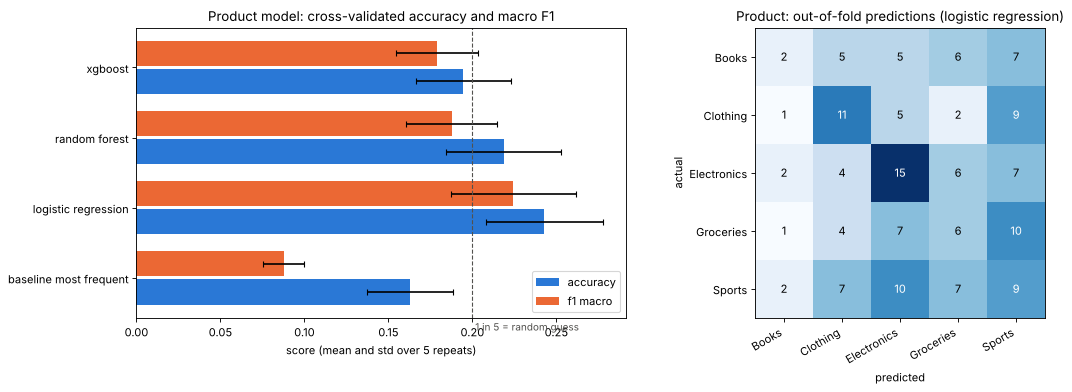

,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,log_loss_mean,log_loss_std
baseline_most_frequent,0.163,0.026,0.088,0.012,1.642,0.015
logistic_regression,0.243,0.035,0.224,0.037,1.698,0.016
random_forest,0.219,0.034,0.188,0.027,1.750,0.010
xgboost,0.195,0.028,0.179,0.024,1.890,0.045


In [8]:
comparison = pd.DataFrame(product.metrics["comparison"]).T
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.2, 1]})
names = [n.replace("_", " ") for n in comparison.index]
y = np.arange(len(names))
for offset, metric, colour in [(-0.2, "accuracy", "#2a78d6"), (0.2, "f1_macro", "#eb6834")]:
    axes[0].barh(y + offset, comparison[f"{metric}_mean"], height=0.36, xerr=comparison[f"{metric}_std"],
                 color=colour, label=metric.replace("_", " "), capsize=3)
axes[0].set_yticks(y, names)
axes[0].axvline(1 / len(product.classes), color="#52514e", ls="--", lw=1)
axes[0].text(1 / len(product.classes), -0.75, " 1 in 5 = random guess", color="#52514e", fontsize=9)
axes[0].set_xlabel("score (mean and std over 5 repeats)")
axes[0].set_title("Product model: cross-validated accuracy and macro F1")
axes[0].legend(loc="lower right")
plot_confusion(axes[1], product.metrics["confusion_matrix"], product.classes,
               f"Product: out-of-fold predictions ({product.model_name.replace('_', ' ')})")
fig.tight_layout()
plt.show()
cols = ["accuracy_mean", "accuracy_std", "f1_macro_mean", "f1_macro_std", "log_loss_mean", "log_loss_std"]
display(comparison[cols].round(3))

**Interpretation:** the product category is close to unpredictable from these features. Logistic Regression is best
(accuracy 0.243, F1 0.224), above the baseline (0.163, 0.088) and random guessing (0.20), but only slightly, and its
log loss (1.698) is worse than the baseline's (1.642). The features describe how engaged a customer is, not what they
like: the EDA showed almost the same purchase interest in every category. The app therefore shows every category
ranked by probability rather than one confident answer.

## 6. Summary of the three models

In [9]:
summary = pd.DataFrame({
    "facial recognition": {"model": face.model_name, **face.metrics["closed_set"],
                           "evaluation": "leave one photo out"},
    "voiceprint verification": {"model": voice.model_name, **voice.metrics["closed_set"],
                                "evaluation": "leave one recording out"},
    "product recommendation": {"model": product.model_name, "accuracy": product.metrics["cv"]["accuracy_mean"],
                               "f1_macro": product.metrics["cv"]["f1_macro_mean"],
                               "log_loss": product.metrics["cv"]["log_loss_mean"],
                               "evaluation": "5x5-fold CV grouped by customer"},
}).T
display(summary.round(3))

,model,accuracy,f1_macro,log_loss,evaluation
facial recognition,logistic_regression,0.916667,0.914286,0.176931,leave one photo out
voiceprint verification,logistic_regression,0.72449,0.629022,1.001595,leave one recording out
product recommendation,logistic_regression,0.242667,0.224385,1.698103,5x5-fold CV grouped by customer


## 7. System simulation

The cells below run the same code as `python app.py --demo`. Each scenario follows the system flow: face, then the
product model, then the voice, and the prediction is only shown when every check passes.

**Stranger samples.** Scenarios 3 and 4 use a photo and a voice clip of Ketia, who is not a team member
(`data/unauthorized/`, never used for training). Without such files, the demo simulates a stranger by enrolling the
team without one member.

In [10]:
import app

system = app.RecommendationSystem()
app.run_demo(system)



  SCENARIO 1: authorised transaction by alain



Step 1 - Face recognition: alain_neutral.jpg


  [PASS] matches alain (confidence 1.00, similarity 0.93)


  Welcome, alain.



Step 2 - Product recommendation model


  [PASS] prediction computed for customer 187; held until the voice check approves it


... (31 outputs left out)

  1. GRANTED  authorised transaction by alain


  2. DENIED   arnold uses alain's face but confirms with their own voice


  3. DENIED   a stranger (not in the team) tries to log in


  4. DENIED   alain's face, but a stranger's voice approves


### Running the app yourself

From the repository root, on Windows, macOS or Linux:

```bash
python app.py --demo                                   # the scenarios above
python app.py                                          # interactive: asks for a photo, then a voice clip
python app.py --face data/images/desire/desire_neutral.jpg --voice data/audio/desire/desire_yes_approve_1.wav
python app.py --face my_photo.heic --voice my_voice.m4a --customer-id 120 --date 2026-12-01
```

Photos and recordings can be in any common format. The app exits with code 0 when access is granted and 1 when it is
denied. Each member is linked to a customer account in `data/member_accounts.csv`, and `--customer-id` overrides it.

**Interpretation:**

1. **Authorised:** Alain's face (1.00, similarity 0.93) and voice (0.96, 0.94) pass, and only then is his
   recommendation shown.
2. **Teammate fraud:** Arnold uses Alain's photo. The face passes, but his voice scores 0.014 for Alain: denied.
3. **Stranger's face:** Ketia's best match is Desire at 0.518, below 0.80 (similarity 0.20): denied at step 1.
4. **Stranger's voice:** on Alain's session, Ketia's voice scores 0.368 for Alain, below 0.50: denied.

The voice is checked against the member the face recognised, so a teammate cannot approve someone else's transaction.
The voice check is not perfect: it rejects 80% of strangers (section 4), and Ketia's voice would have passed if the
face check had matched her to Desire.